# 可选实验：特征工程与多项式回归

![](./images/C1_W2_Lab07_FeatureEngLecture.PNG)

## 学习目标
在本实验中，你将：
- 探索特征工程和多项式回归，它们能让你使用线性回归的机制来拟合非常复杂、甚至高度非线性的函数。

## 工具
你将使用之前实验中开发的函数，以及 matplotlib 和 NumPy。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lab_utils_multi import zscore_normalize_features, run_gradient_descent_feng
np.set_printoptions(precision=2)  # reduced display precision on numpy arrays

<a name='FeatureEng'></a>
# 特征工程与多项式回归概述

开箱即用的线性回归提供了一种构建如下形式模型的方法：
$$f_{\mathbf{w},b} = w_0x_0 + w_1x_1+ ... + w_{n-1}x_{n-1} + b \tag{1}$$
如果你的特征/数据是非线性的，或者是特征的组合，该怎么办？例如，房价往往并不与居住面积呈线性关系，而是会对过小或过大的房屋加以"惩罚"，从而形成上图所示的曲线。我们如何使用线性回归的机制来拟合这条曲线？回顾一下，我们拥有的"机制"是能够修改 (1) 中的参数 $\mathbf{w}$、$\mathbf{b}$，以将方程"拟合"到训练数据。然而，无论如何调整 (1) 中的 $\mathbf{w}$、$\mathbf{b}$，都无法拟合一条非线性曲线。

<a name='PolynomialFeatures'></a>
## 多项式特征

上面我们考虑的是一种数据为非线性的情形。让我们尝试用目前所学的知识来拟合一条非线性曲线。我们先从一个简单的二次函数开始：$y = 1+x^2$

你已经熟悉我们要用的所有程序。它们都在 lab_utils.py 文件中，可供复习。我们将使用 [`np.c_[..]`](https://numpy.org/doc/stable/reference/generated/numpy.c_.html)，这是一个沿列边界进行拼接的 NumPy 程序。

Iteration         0, Cost: 1.65756e+03
Iteration       100, Cost: 6.94549e+02
Iteration       200, Cost: 5.88475e+02
Iteration       300, Cost: 5.26414e+02
Iteration       400, Cost: 4.90103e+02
Iteration       500, Cost: 4.68858e+02
Iteration       600, Cost: 4.56428e+02
Iteration       700, Cost: 4.49155e+02
Iteration       800, Cost: 4.44900e+02
Iteration       900, Cost: 4.42411e+02
w,b found by gradient descent: w: [18.7], b: -52.0834


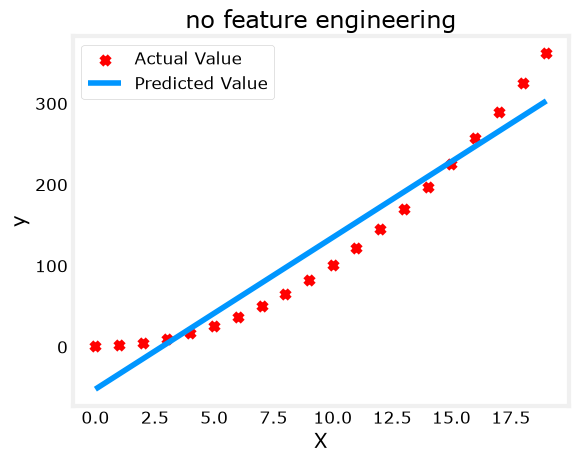

In [19]:
# create target data
x = np.arange(0, 20, 1)
y = 1 + x**2
X = x.reshape(-1, 1)

model_w,model_b = run_gradient_descent_feng(X,y,iterations=1000, alpha = 1e-2)

plt.scatter(x, y, marker='x', c='r', label="Actual Value"); plt.title("no feature engineering")
plt.plot(x,X@model_w + model_b, label="Predicted Value");  plt.xlabel("X"); plt.ylabel("y"); plt.legend(); plt.show()

嗯，正如预期，拟合得并不好。我们需要的是像 $y= w_0x_0^2 + b$ 这样的形式，即一个**多项式特征**。
要做到这一点，你可以修改*输入数据*来*构造*（engineer）所需的特征。如果你把原始数据替换为对 $x$ 值取平方的版本，那么你就可以得到 $y= w_0x_0^2 + b$。让我们来试试。在下面把 `X` 换成 `X**2`：

In [3]:
# create target data
x = np.arange(0, 20, 1)
y = 1 + x**2

# Engineer features 
X = x**2      #<-- added engineered feature

Iteration         0, Cost: 7.32922e+03
Iteration      1000, Cost: 2.24844e-01
Iteration      2000, Cost: 2.22795e-01
Iteration      3000, Cost: 2.20764e-01
Iteration      4000, Cost: 2.18752e-01
Iteration      5000, Cost: 2.16758e-01
Iteration      6000, Cost: 2.14782e-01
Iteration      7000, Cost: 2.12824e-01
Iteration      8000, Cost: 2.10884e-01
Iteration      9000, Cost: 2.08962e-01
w,b found by gradient descent: w: [1.], b: 0.0490


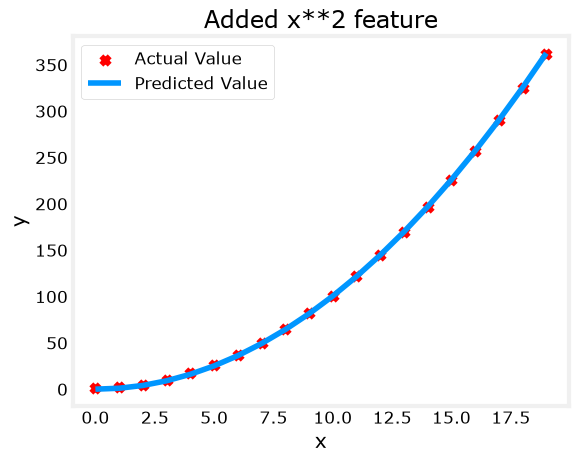

In [4]:
X = X.reshape(-1, 1)  #X should be a 2-D Matrix
model_w,model_b = run_gradient_descent_feng(X, y, iterations=10000, alpha = 1e-5)

plt.scatter(x, y, marker='x', c='r', label="Actual Value"); plt.title("Added x**2 feature")
plt.plot(x, np.dot(X,model_w) + model_b, label="Predicted Value"); plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

太好了！几乎完美拟合。请注意在图的上方打印出的 $\mathbf{w}$ 和 b 的值：`w,b found by gradient descent: w: [1.], b: 0.0490`。梯度下降将我们 $\mathbf{w},b $ 的初始值修改为 (1.0,0.049)，即模型 $y=1*x_0^2+0.049$，非常接近我们的目标 $y=1*x_0^2+1$。如果你运行更长时间，它可能会匹配得更好。

### 选择特征
<a name='GDF'></a>
在上面，我们知道需要一个 $x^2$ 项。但需要哪些特征并不总是那么明显。你可以添加各种潜在的特征，尝试找出最有用的那些。例如，如果我们改用 $y=w_0x_0 + w_1x_1^2 + w_2x_2^3+b$ 会怎样？

运行接下来的单元格。

In [5]:
# create target data
x = np.arange(0, 20, 1)
y = x**2

# engineer features .
X = np.c_[x, x**2, x**3]   #<-- added engineered feature

Iteration         0, Cost: 1.14029e+03
Iteration      1000, Cost: 3.28539e+02
Iteration      2000, Cost: 2.80443e+02
Iteration      3000, Cost: 2.39389e+02
Iteration      4000, Cost: 2.04344e+02
Iteration      5000, Cost: 1.74430e+02
Iteration      6000, Cost: 1.48896e+02
Iteration      7000, Cost: 1.27100e+02
Iteration      8000, Cost: 1.08495e+02
Iteration      9000, Cost: 9.26132e+01
w,b found by gradient descent: w: [0.08 0.54 0.03], b: 0.0106


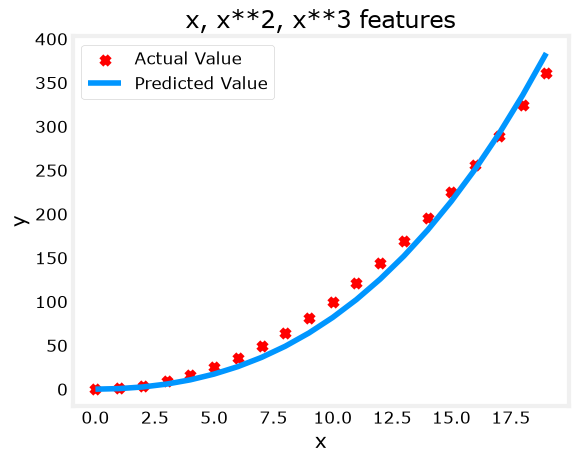

In [6]:
model_w,model_b = run_gradient_descent_feng(X, y, iterations=10000, alpha=1e-7)

plt.scatter(x, y, marker='x', c='r', label="Actual Value"); plt.title("x, x**2, x**3 features")
plt.plot(x, X@model_w + model_b, label="Predicted Value"); plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

请注意 $\mathbf{w}$ 的值 `[0.08 0.54 0.03]`，b 为 `0.0106`。这意味着经过拟合/训练后的模型为：
$$ 0.08x + 0.54x^2 + 0.03x^3 + 0.0106 $$
梯度下降通过相对增大 $w_1$ 项，强调了最契合 $x^2$ 数据的部分。如果你运行非常长的时间，它会继续减小其他项的影响。
>梯度下降通过强调某特征所关联的参数，来为我们挑选"正确"的特征

让我们回顾一下这个思路：
- 一开始，各特征被重新缩放，使它们彼此可比
- 权重值越小意味着该特征越不重要/越不正确；在极端情况下，当权重变为零或非常接近零时，所关联的特征对拟合模型没有用处。
- 在上面，拟合之后，与 $x^2$ 特征关联的权重远大于 $x$ 或 $x^3$ 的权重，因为它在拟合数据时最有用。

### 另一种视角
在上面，多项式特征是根据它们与目标数据的匹配程度来选择的。另一种理解方式是注意到：一旦我们创建了新特征，仍然是在使用线性回归。既然如此，最好的特征相对于目标应当是线性的。用一个例子最容易理解这一点。

In [7]:
# create target data
x = np.arange(0, 20, 1)
y = x**2

# engineer features .
X = np.c_[x, x**2, x**3]   #<-- added engineered feature
X_features = ['x','x^2','x^3']

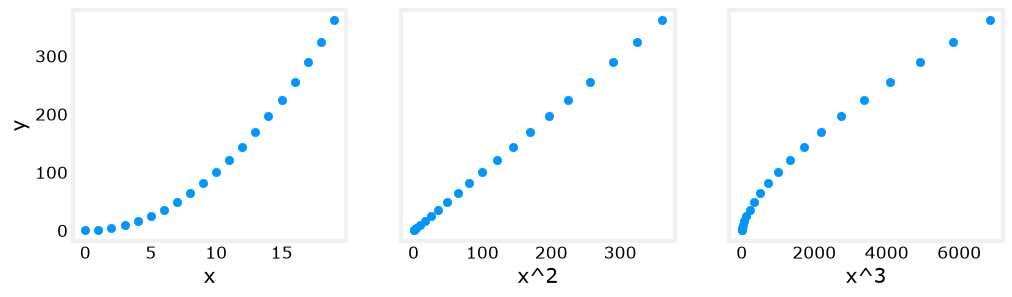

In [8]:
fig,ax=plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for i in range(len(ax)):
    ax[i].scatter(X[:,i],y)
    ax[i].set_xlabel(X_features[i])
ax[0].set_ylabel("y")
plt.show()

在上面，显然 $x^2$ 特征相对于目标值 $y$ 是线性的。于是线性回归就可以很容易地使用该特征生成一个模型。

### 缩放特征
如上一个实验所述，如果数据集中各特征的尺度差异显著，就应当应用特征缩放来加速梯度下降。在上面的例子中，有 $x$、$x^2$ 和 $x^3$，它们自然会具有非常不同的尺度。让我们对例子应用 Z-score 归一化。

In [9]:
# create target data
x = np.arange(0,20,1)
X = np.c_[x, x**2, x**3]
print(f"Peak to Peak range by column in Raw        X:{np.ptp(X,axis=0)}")

# add mean_normalization 
X = zscore_normalize_features(X)     
print(f"Peak to Peak range by column in Normalized X:{np.ptp(X,axis=0)}")

Peak to Peak range by column in Raw        X:[  19  361 6859]
Peak to Peak range by column in Normalized X:[3.3  3.18 3.28]


现在我们可以用一个更激进的 alpha 值再试一次：

Iteration         0, Cost: 9.42147e+03
Iteration     10000, Cost: 3.90938e-01
Iteration     20000, Cost: 2.78389e-02
Iteration     30000, Cost: 1.98242e-03
Iteration     40000, Cost: 1.41169e-04
Iteration     50000, Cost: 1.00527e-05
Iteration     60000, Cost: 7.15855e-07
Iteration     70000, Cost: 5.09763e-08
Iteration     80000, Cost: 3.63004e-09
Iteration     90000, Cost: 2.58497e-10
w,b found by gradient descent: w: [5.27e-05 1.13e+02 8.43e-05], b: 123.5000


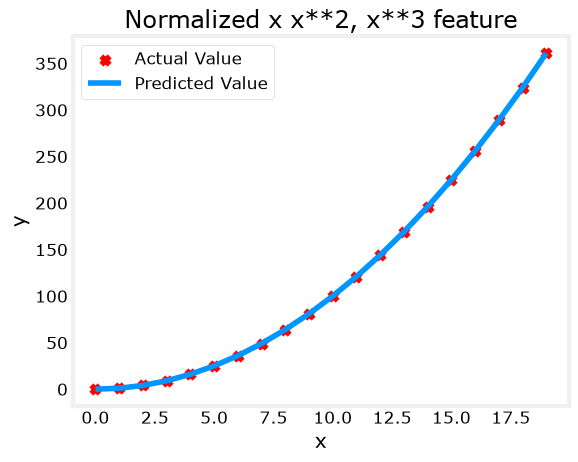

In [10]:
x = np.arange(0,20,1)
y = x**2

X = np.c_[x, x**2, x**3]
X = zscore_normalize_features(X) 

model_w, model_b = run_gradient_descent_feng(X, y, iterations=100000, alpha=1e-1)

plt.scatter(x, y, marker='x', c='r', label="Actual Value"); plt.title("Normalized x x**2, x**3 feature")
plt.plot(x,X@model_w + model_b, label="Predicted Value"); plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

特征缩放使其收敛得快得多。
再次注意 $\mathbf{w}$ 的值。$w_1$ 项，也就是 $x^2$ 项，被强调得最多。梯度下降几乎已经消除了 $x^3$ 项。

### 复杂函数
借助特征工程，即使是相当复杂的函数也可以被建模：

Iteration         0, Cost: 2.20188e-01
Iteration    100000, Cost: 1.70074e-02
Iteration    200000, Cost: 1.27603e-02
Iteration    300000, Cost: 9.73032e-03
Iteration    400000, Cost: 7.56440e-03
Iteration    500000, Cost: 6.01412e-03
Iteration    600000, Cost: 4.90251e-03
Iteration    700000, Cost: 4.10351e-03
Iteration    800000, Cost: 3.52730e-03
Iteration    900000, Cost: 3.10989e-03
w,b found by gradient descent: w: [ -1.34 -10.    24.78   5.96 -12.49 -16.26  -9.51   0.59   8.7   11.94
   9.27   0.79 -12.82], b: -0.0073


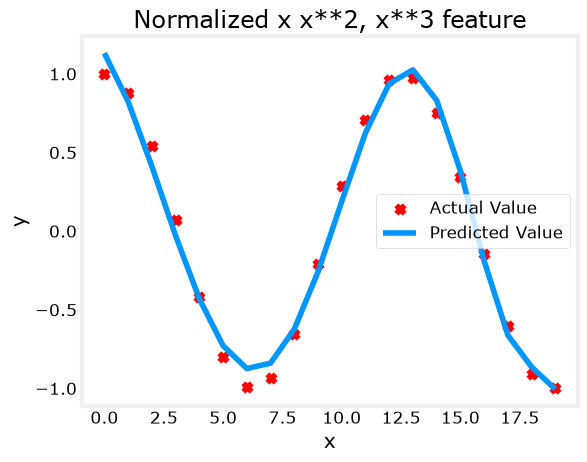

In [11]:
x = np.arange(0,20,1)
y = np.cos(x/2)

X = np.c_[x, x**2, x**3,x**4, x**5, x**6, x**7, x**8, x**9, x**10, x**11, x**12, x**13]
X = zscore_normalize_features(X) 

model_w,model_b = run_gradient_descent_feng(X, y, iterations=1000000, alpha = 1e-1)

plt.scatter(x, y, marker='x', c='r', label="Actual Value"); plt.title("Normalized x x**2, x**3 feature")
plt.plot(x,X@model_w + model_b, label="Predicted Value"); plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()



## 恭喜完成！
在本实验中，你：
- 学会了线性回归如何借助特征工程来建模复杂的、甚至高度非线性的函数
- 认识到在做特征工程时应用特征缩放很重要